In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import shapiro, levene, f_oneway, pearsonr, chisquare
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import statsmodels.api as sm
from src import bootstrap_mean_difference_ci

# Dataset description and report goal

A fast-food chain plans to add a new item to its menu. However, they are still undecided between three possible marketing campaigns for promoting the new product. In order to determine which promotion has the greatest effect on sales, the new item is introduced at locations in several randomly selected markets. A different promotion is used at each location, and the weekly sales of the new item are recorded for the first four weeks.

**Goal**

Evaluate A/B testing results and decide which marketing strategy works the best.

**Columns**

* **MarketID**: unique identifier for market
* **MarketSize**: size of market area by sales
* **LocationID**: unique identifier for store location
* **AgeOfStore**: age of store in years
* **Promotion**: one of three promotions that were tested
* **week**: one of four weeks when the promotions were run
* **SalesInThousands**: sales amount for a specific LocationID, Promotion, and week


# Analysis plan

1. **Data Loading and Initial Inspection**: Load the dataset and perform an initial check of its structure, types, and summary statistics.

2. **Exploratory Data Analysis (EDA)**: Understand the distributions of key variables, identify potential outliers, and visualize relationships, especially between Promotion and SalesInThousands.

3. **Hypothesis Formulation**: Clearly define the null and alternative hypotheses for our A/B test.

4. **Assumptions Check for Statistical Tests**: Verify the assumptions required for the chosen statistical test (e.g., ANOVA).

5. **Statistical Test Implementation and Interpretation of Results**: Perform the appropriate statistical test to compare the sales performance across different promotions. Interpret the p-value and other relevant statistics from the test.

6. **Post-Hoc Analysis**: If the primary test shows a significant difference, conduct post-hoc tests to identify which specific promotion groups differ.

7. **Other possible analysis angles**: because there are several categorical variables, it should be usefull to check if there is any correlation between them and our results.

8. **Conclusion and Recommendations**: Summarize findings and provide actionable insights.

# 1. Data Loading and Initial Data Inspection

In [3]:
df = pd.read_csv("WA_Marketing-Campaign.csv")

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 548 entries, 0 to 547
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   MarketID          548 non-null    int64  
 1   MarketSize        548 non-null    object 
 2   LocationID        548 non-null    int64  
 3   AgeOfStore        548 non-null    int64  
 4   Promotion         548 non-null    int64  
 5   week              548 non-null    int64  
 6   SalesInThousands  548 non-null    float64
dtypes: float64(1), int64(5), object(1)
memory usage: 30.1+ KB


In [5]:
df.head()

,MarketID,MarketSize,LocationID,AgeOfStore,Promotion,week,SalesInThousands
0,1,Medium,1,4,3,1,33.73
1,1,Medium,1,4,3,2,35.67
2,1,Medium,1,4,3,3,29.03
3,1,Medium,1,4,3,4,39.25
4,1,Medium,2,5,2,1,27.81


Initial data view confirms Kagle description of dataset structure. There is no empty values, but categorical variables are not marked as such. They codes as `int` so I will make data categorical for ease of analysis. 

In [6]:
df['MarketID'] = df['MarketID'].astype('category')
df['LocationID'] = df['LocationID'].astype('category')
df['week'] = df['week'] .astype('category')

promo_map = {1: 'promo_1', 2: 'promo_2', 3: 'promo_3'}
df['Promotion'] = df['Promotion'].map(promo_map)

In [7]:
sns.set_theme(style="whitegrid", palette="pastel") 

## 2. Exploratory Data Analysis (EDA)

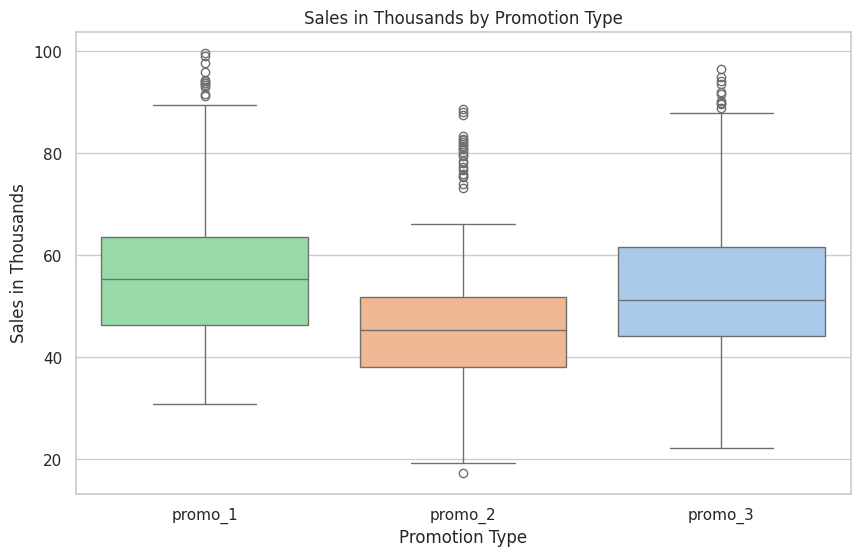

In [8]:
plt.figure(figsize=(10,6))
sns.boxplot(x="Promotion", y="SalesInThousands", data=df, hue="Promotion", order=["promo_1", "promo_2", "promo_3"])    
plt.title('Sales in Thousands by Promotion Type')
plt.xlabel('Promotion Type')
plt.ylabel('Sales in Thousands')
plt.show()


Data set have some outliers, but I will not remove them, because they are real data and not so far from the mean. They are very close to upper bound of the boxplot.

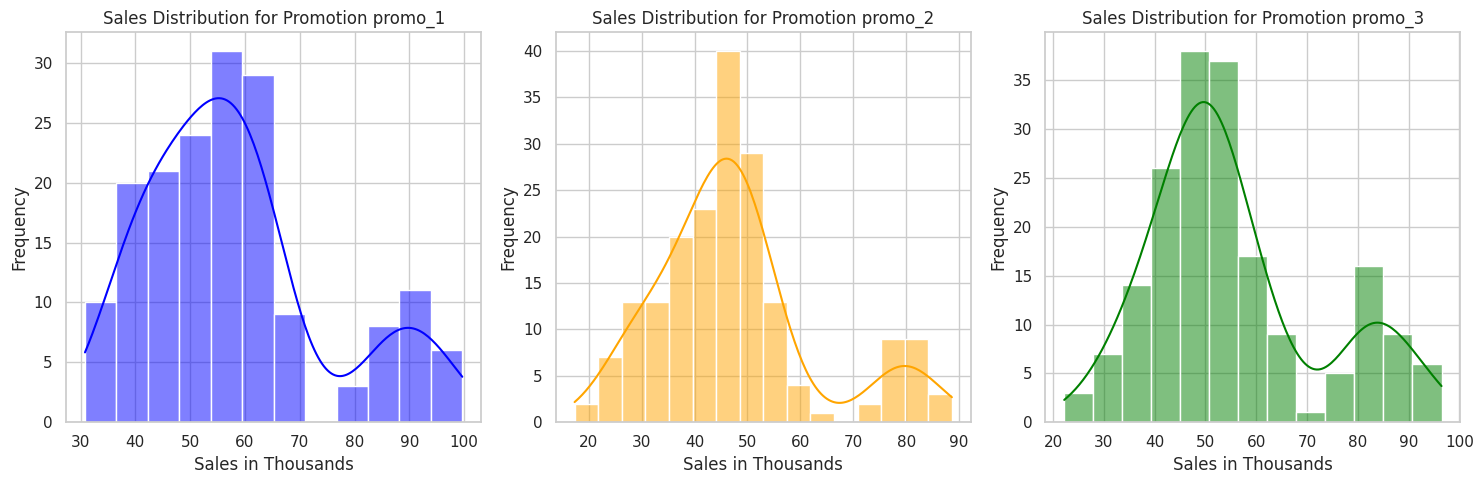

In [9]:
plt.figure(figsize=(15, 5))
promotion_types = df['Promotion'].sort_values().unique()

colors = ['blue','orange',  'green']
for i, promo in enumerate(promotion_types):
    plt.subplot(1, len(promotion_types), i + 1)
    sns.histplot(df[df['Promotion'] == promo]['SalesInThousands'], kde=True, color=colors[i])
    plt.title(f'Sales Distribution for Promotion {promo}')
    plt.xlabel('Sales in Thousands')
    plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

**Visualized the distribution of `SalesInThousands` for each Promotion:**

* I've created a box plot which helps to visually compare the median sales, spread, and potential outliers for each promotion type.

* I've also generated histograms for each promotion type, which show the shape of the sales distribution for `promo_1`, `promo_ 2`, and `promo_3` individually. This is nessesary to check if the data is normally distributed for further analysis.

**Calculated summary statistics for `SalesInThousands` grouped by Promotion:**

* `promo_1`:
    * Count: 172  
    * Mean Sales: 58.099  
    * Median Sales: 55.385  
    * Standard Deviation: 16.554  
    * Minimum Sales: 30.81  
    * Maximum Sales: 99.65  

* `promo_2`:
    * Count: 188  
    * Mean Sales: 47.329  
    * Median Sales: 45.385  
    * Standard Deviation: 15.109
    * Minimum Sales: 17.34
    * Maximum Sales: 88.64

* `promo_3`:
    * Count: 188 
    * Mean Sales: 55.364
    * Median Sales: 51.165
    * Standard Deviation: 16.766
    * Minimum Sales: 22.18
    * Maximum Sales: 96.48


**Observations from EDA:**

* From the summary statistics and the box plot, it appears that `promo_1` has the highest mean and median sales, followed by `promo_3`, and then `promo_2`.

* The spread of sales (standard deviation and the boxes in the box plot) seems somewhat similar across the promotions, but `promo_1` and `promo_3` show slightly higher variability compared to `promo_2`.

* There might be some outliers, especially for `promo_1` and `promo_3`, visible as individual points beyond the "whiskers" of the box plots.

In [10]:
print("\nSummary statistics of SalesInThousands grouped by Promotion:\n")
summary_stats = df.groupby('Promotion')['SalesInThousands'].agg(['count', 'mean', 'median', 'std', 'min', 'max'])
print(summary_stats)


Summary statistics of SalesInThousands grouped by Promotion:

           count       mean  median        std    min    max
Promotion                                                   
promo_1      172  58.099012  55.385  16.553782  30.81  99.65
promo_2      188  47.329415  45.385  15.108955  17.34  88.64
promo_3      188  55.364468  51.165  16.766231  22.18  96.48


We see that all promotions have very similar total numbers. Only `promo_1` has slightly smaller number - 172, as `promo_2` and `promo_3` have 188. The difference is verys small, but I will check if it statistically significant by checking for SRM (Sample Ratio Mismatch).

In [11]:
observed_counts = df['Promotion'].value_counts().sort_index()
print("\nObserved counts for each Promotion type:")
print(observed_counts)

total_observations = observed_counts.sum()
print(f"\nTotal observations: {total_observations}")

num_promotions = len(observed_counts)
expected_count_per_promotion = total_observations / num_promotions
expected_counts = [expected_count_per_promotion] * num_promotions
print(f"Expected count per Promotion (assuming equal split): {expected_count_per_promotion:.2f}")

chi2_stat_srm, p_value_srm = chisquare(f_obs=observed_counts, f_exp=expected_counts)

print("\n--- Chi-squared Test for SRM ---")
print(f"Chi-squared Statistic (SRM): {chi2_stat_srm:.3f}")
print(f"P-value (SRM): {p_value_srm:.3f}")



Observed counts for each Promotion type:
Promotion
promo_1    172
promo_2    188
promo_3    188
Name: count, dtype: int64

Total observations: 548
Expected count per Promotion (assuming equal split): 182.67

--- Chi-squared Test for SRM ---
Chi-squared Statistic (SRM): 0.934
P-value (SRM): 0.627


Chi-square test P-value is 0,627, which is higher that 0.05, so with alpha 0.05 we can't reject the null hypothesis. This means that there is no statisticaly significant sample ratio mismatch.

 As there are diferent locations is interesting to know how much unique locations are and how promotion were distributed between locations

In [12]:
unq_locations = df['LocationID'].nunique()
print(f"\nThere are {unq_locations} unique locations in the dataset.")

promotion_distribution_by_location = df.groupby(['LocationID', 'Promotion'], observed=True).size().unstack(fill_value=0)
print("\nDistribution of Promotions by LocationID:")
print(promotion_distribution_by_location)


There are 137 unique locations in the dataset.

Distribution of Promotions by LocationID:
Promotion   promo_1  promo_2  promo_3
LocationID                           
1                 0        0        4
2                 0        4        0
3                 4        0        0
4                 0        4        0
5                 0        4        0
...             ...      ...      ...
916               0        4        0
917               0        0        4
918               4        0        0
919               4        0        0
920               0        4        0

[137 rows x 3 columns]


It seems that each `LocationID` was assigned a single `Promotion` for the entire duration of the test. This simplifies the analysis because we are comparing sales from distinct groups of stores, each under a specific promotion, rather than comparing different promotions within the same store over time.

# 3. Hypothesis Formulation

In A/B testing, especially when comparing more than two groups (in your case, three promotion types), we use statistical hypotheses to frame our analysis. Since we are comparing the mean sales across three distinct groups, the appropriate statistical test will be Analysis of Variance (ANOVA).

Here are the hypotheses for your A/B test:

* **Null Hypothesis (H0):** There is no statistically significant difference in the mean sales (`SalesInThousands`) among the different promotion types.

    * In other words, any observed differences in average sales are due to random chance.
    * Mathematically: μ1=μ2=μ3 (where μi represents the true mean sales for Promotion type i).

* **Alternative Hypothesis (Ha):** At least one promotion type has a statistically significant different mean sales (`SalesInThousands`) compared to the others.

    * This means that the promotions do have an effect on sales.
    * Mathematically: Not all μi​ are equal.
    


# 4. Assumptions Check for Statistical Tests

Before we apply the ANOVA test to compare the mean sales across the different promotions, it's important to verify that our data meets the assumptions of the ANOVA test. Violating these assumptions can lead to unreliable results.

The key assumptions for ANOVA are:

* **Independence of Observations**: Each observation (i.e., each row of sales data) must be independent of every other observation. Given that each LocationID was assigned a single promotion, and we are treating each weekly sales record from a distinct store under a specific promotion as an independent observation, this assumption is generally met by the experimental design.

* **Normality**: The `SalesInThousands` for each promotion group should be approximately normally distributed. ANOVA is somewhat robust to minor deviations from normality, especially with larger sample sizes (which we have: 172, 188, and 188 observations per group). From our previous visualizations, we can see that the data is not perfectly normal, but it is close enough to assume normality. I will use the Shapiro-Wilk test to check for normality with Q-Q plot for visualization.

* **Homogeneity of Variances (Homoscedasticity)**: The variance of `SalesInThousands` should be roughly equal across all promotion groups. This is often the most critical assumption to check. For this, I will use the Levene test.

Let's check the Normality and Homogeneity of Variances using statistical tests and by revisiting our visualizations.

Promotion promo_1 Shapiro-Wilk Test Statistic: 0.915, p-value: 0.0000000198
Promotion promo_2 Shapiro-Wilk Test Statistic: 0.915, p-value: 0.0000000055
Promotion promo_3 Shapiro-Wilk Test Statistic: 0.921, p-value: 0.0000000150

Levene's Test Statistic: 1.270, p-value: 0.282


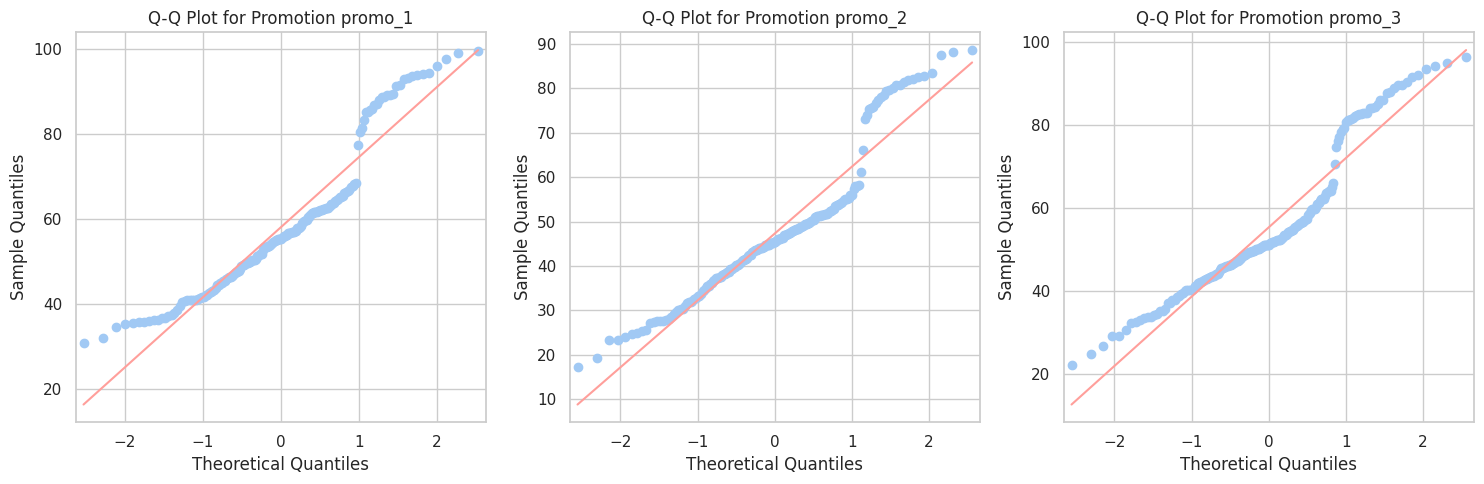

In [13]:
for promo_type in promotion_types:
    sales_data = df[df['Promotion'] == promo_type]['SalesInThousands']
    stat, p_shapiro = shapiro(sales_data)
    print(f"Promotion {promo_type} Shapiro-Wilk Test Statistic: {stat:.3f}, p-value: {p_shapiro:.10f}")

plt.figure(figsize=(15, 5))
for i, promo_type in enumerate(promotion_types):
    ax = plt.subplot(1, len(df['Promotion'].unique()), i + 1)
    sm.qqplot(df[df['Promotion'] == promo_type]['SalesInThousands'], line='s', ax=ax)
    ax.set_title(f'Q-Q Plot for Promotion {promo_type}')
plt.tight_layout()

promo1_sales = df[df['Promotion'] == 'promo_1']['SalesInThousands']
promo2_sales = df[df['Promotion'] == 'promo_2']['SalesInThousands']
promo3_sales = df[df['Promotion'] == 'promo_3']['SalesInThousands']

stat_levene, p_levene = levene(promo1_sales, promo2_sales, promo3_sales)
print(f"\nLevene's Test Statistic: {stat_levene:.3f}, p-value: {p_levene:.3f}")


**Normality Check** (Shapiro-Wilk Test and Q-Q Plots)

* `promo_3`: Shapiro-Wilk Test Statistic: 0.921, p-value: 0.000. Sales do not appear to be normally distributed (p <= 0.05).

* `promo_2`: Shapiro-Wilk Test Statistic: 0.915, p-value: 0.000. Sales do not appear to be normally distributed (p <= 0.05).

* `promo_1`: Shapiro-Wilk Test Statistic: 0.915, p-value: 0.000. Sales do not appear to be normally distributed (p <= 0.05).

The Shapiro-Wilk test indicates that the sales data for all three promotion groups are not normally distributed (p-values are less than 0.05). You can also visually inspect the Q-Q plots where the points deviate from the straight line, confirming non-normality. But again as was mentioned before data non-normality is not so high that it would be a problem for our analysis.

**Homogeneity of Variances** Check (Levene's Test)

* Levene's Test Statistic: 1.270, p-value: 0.282.

* Result: The variances appear to be equal across promotion groups (p > 0.05).

This means the assumption of homogeneity of variances is met. **This also refer back to our EDA where the boxplots are visually quite similar across the promotions.**


# 5. Statistical Test Implementation (One-Way ANOVA) and result interpretation

In [14]:
f_statistic, p_value_anova = f_oneway(promo1_sales, promo2_sales, promo3_sales)

print(f"ANOVA F-statistic: {f_statistic:.3f}")
print(f"ANOVA p-value: {p_value_anova:.10f}")

ANOVA F-statistic: 21.953
ANOVA p-value: 0.0000000007


**Here are the results:**

* ANOVA F-statistic: 21.953

* ANOVA p-value: 0.0000000007

**Interpretation of Results:**

* Since the p-value (0.000) is much less than our common significance level of 0.05, we **reject the null hypothesis (H_0)**.

* This means **there is a statistically significant difference in mean** sales among the different promotion types. In other words, the type of promotion does have a statistically significant effect on sales.

Because the ANOVA test only tells us that at least one group mean is different, but not which specific groups differ, we now need to perform Post-Hoc Analysis. This will help us pinpoint exactly which promotion pairs (e.g., `promo_1` vs. `promo_2`, `promo_1` vs. `promo_3`, `promo_2` vs. `promo_3`) have statistically significant differences in their mean sales.

# 6. Post-Hoc Analysis using Tukey's HSD test

In [15]:
tukey_result = pairwise_tukeyhsd(endog=df['SalesInThousands'],
                                 groups=df['Promotion'],
                                 alpha=0.05)

tukey_result.summary()

group1,group2,meandiff,p-adj,lower,upper,reject
promo_1,promo_2,-10.7696,0.0,-14.7738,-6.7654,True
promo_1,promo_3,-2.7345,0.2444,-6.7388,1.2697,False
promo_2,promo_3,8.0351,0.0,4.1208,11.9493,True


**Interpretation of Post-Hoc Results:**

* `promo_2` vs `promo_1` :

    * Mean Difference: -10.7696
    * p-adj: 0.000
    * Reject: True  

    Interpretation: There is a statistically significant difference in mean sales between promo_1 and promo_2. promo_1 performed significantly better (higher mean sales) than promo_2, as indicated by the negative mean difference (Mean Sales of promo_1 - Mean Sales of promo_2).

* `promo_3` vs `promo_1` :

    * Mean Difference: -2.7345
    * p-adj: 0.2444
    * Reject: False

    Interpretation: There is no statistically significant difference in mean sales between promo_1 and promo_3.

* `promo_3` vs `promo_2` :

    * Mean Difference: 8.0351
    * p-adj: 0.000
    * Reject: True

    Interpretation: There is a statistically significant difference in mean sales between promo_2 and promo_3. promo_3 performed significantly better (higher mean sales) than promo_2, as indicated by the positive mean difference (Mean Sales of promo_2 - Mean Sales of promo_3).

Summary of Findings from Post-Hoc Analysis:

* `promo_1` leads to **significantly** higher sales than `promo_2`.
* `promo_3` leads to **significantly** higher sales than `promo_2` 
* There is **no** statistically significant difference in sales performance between `promo_1` and `promo_3`.

**This means that both promo_1 and promo_3 are significantly better than promo_2, but there's no clear winner between promo_1 and promo_3 based on statistical significance.**

From Tukey's HSD test result I will plot a bar chart for each promotion to visually illustrate results.

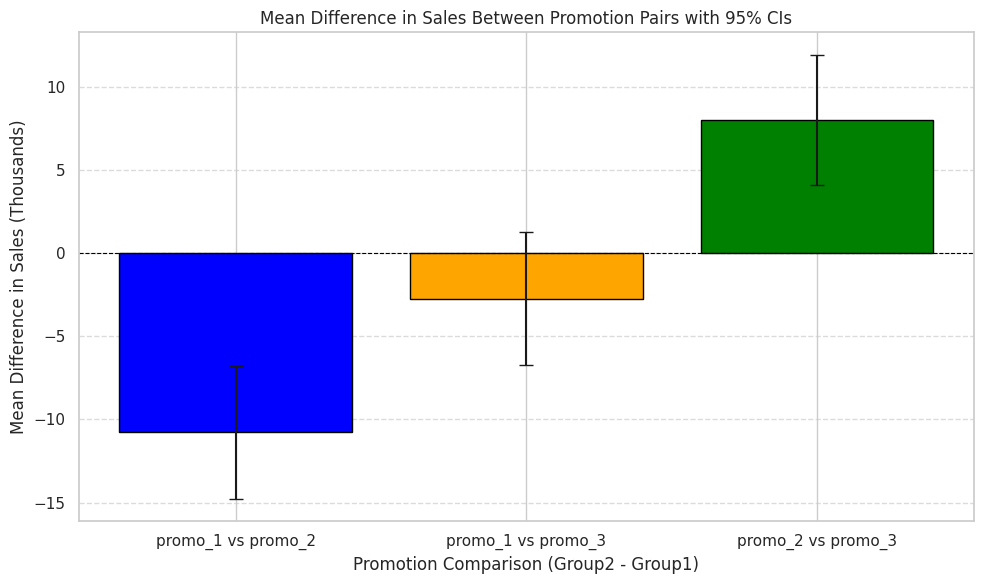

In [16]:
# Convert the summary table to a DataFrame for easier plotting
# The ._results_table attribute holds the data. The first row is the header.
tukey_summary_df = pd.DataFrame(data=tukey_result._results_table.data[1:],
                                columns=tukey_result._results_table.data[0])

# Rename columns for clarity and consistency (optional, but good practice)
tukey_summary_df.columns = ['group1', 'group2', 'meandiff', 'p_adj', 'lower', 'upper', 'reject']

# Convert numeric columns to appropriate types
numeric_cols = ['meandiff', 'p_adj', 'lower', 'upper']
for col in numeric_cols:
    tukey_summary_df[col] = pd.to_numeric(tukey_summary_df[col])

# Create a 'comparison' column for plot labels
tukey_summary_df['comparison'] = tukey_summary_df['group1'].astype(str) + ' vs ' + tukey_summary_df['group2'].astype(str)

# Calculate error for confidence intervals for matplotlib's yerr argument.
# yerr needs two arrays: [lower_errors, upper_errors] from the mean.
tukey_summary_df['lower_error'] = tukey_summary_df['meandiff'] - tukey_summary_df['lower']
tukey_summary_df['upper_error'] = tukey_summary_df['upper'] - tukey_summary_df['meandiff']

plt.figure(figsize=(10, 6)) # Ensure figure size is consistent with rcParams or manually set

bars = plt.bar(tukey_summary_df['comparison'], tukey_summary_df['meandiff'],
               yerr=[tukey_summary_df['lower_error'], tukey_summary_df['upper_error']],
               capsize=5, # size of the caps on the error bars
               color=colors, # colors based on significance
               edgecolor='black') # border color for bars

plt.axhline(0, color='black', linestyle='--', linewidth=0.8) # Add a horizontal line at zero difference

plt.title("Mean Difference in Sales Between Promotion Pairs with 95% CIs")
plt.xlabel("Promotion Comparison (Group2 - Group1)")
plt.ylabel("Mean Difference in Sales (Thousands)")
plt.grid(axis='y', linestyle='--', alpha=0.7) # Add a horizontal grid
plt.tight_layout() # Adjust layout to prevent labels from overlapping
plt.show()

As data failed normallity test I will use bootstrap method to calculate confidence interval and comapre them with Tukey's HSD results.

--- Bootstrap Confidence Intervals for Mean Sales Differences ---

Promotion 1 vs. Promotion 2:
  Observed Mean Difference (P1 - P2): -10.770
  Bootstrap 95% CI for Mean Difference: [-14.060, -7.469]

Promotion 1 vs. Promotion 3:
  Observed Mean Difference (P1 - P3): -2.735
  Bootstrap 95% CI for Mean Difference: [-6.208, 0.702]

Promotion 2 vs. Promotion 3:
  Observed Mean Difference (P2 - P3): 8.035
  Bootstrap 95% CI for Mean Difference: [4.860, 11.259]


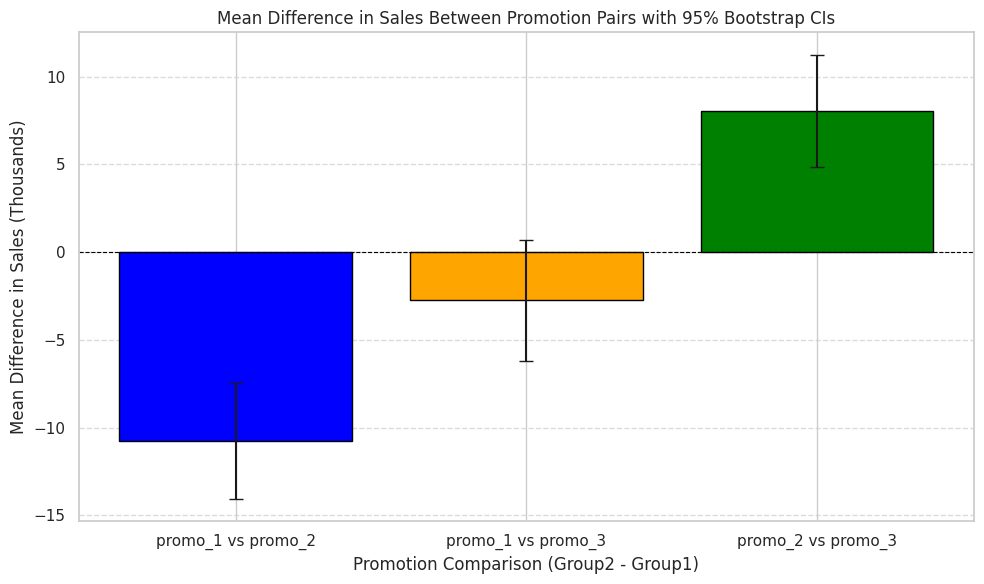

In [17]:
print("--- Bootstrap Confidence Intervals for Mean Sales Differences ---")

# Separate sales data for each promotion group
promo1_sales = df[df['Promotion'] == 'promo_1']['SalesInThousands']
promo2_sales = df[df['Promotion'] == 'promo_2']['SalesInThousands']
promo3_sales = df[df['Promotion'] == 'promo_3']['SalesInThousands']

# Calculate CI for Promotion 1 vs. Promotion 2
print("\nPromotion 1 vs. Promotion 2:")
mean_diff_1_2 = np.mean(promo2_sales) - np.mean(promo1_sales)
lower_ci_1_2, upper_ci_1_2, bootstrap_dist_1_2 = bootstrap_mean_difference_ci(promo1_sales, promo2_sales)
print(f"  Observed Mean Difference (P1 - P2): {mean_diff_1_2:.3f}")
print(f"  Bootstrap 95% CI for Mean Difference: [{lower_ci_1_2:.3f}, {upper_ci_1_2:.3f}]")

# Calculate CI for Promotion 1 vs. Promotion 3
print("\nPromotion 1 vs. Promotion 3:")
mean_diff_1_3 = np.mean(promo3_sales) - np.mean(promo1_sales)
lower_ci_1_3, upper_ci_1_3, bootstrap_dist_1_3 = bootstrap_mean_difference_ci(promo1_sales, promo3_sales)
print(f"  Observed Mean Difference (P1 - P3): {mean_diff_1_3:.3f}")
print(f"  Bootstrap 95% CI for Mean Difference: [{lower_ci_1_3:.3f}, {upper_ci_1_3:.3f}]")

# Calculate CI for Promotion 2 vs. Promotion 3
print("\nPromotion 2 vs. Promotion 3:")
mean_diff_2_3 = np.mean(promo3_sales) - np.mean(promo2_sales)
lower_ci_2_3, upper_ci_2_3, bootstrap_dist_2_3 = bootstrap_mean_difference_ci(promo2_sales, promo3_sales)
print(f"  Observed Mean Difference (P2 - P3): {mean_diff_2_3:.3f}")
print(f"  Bootstrap 95% CI for Mean Difference: [{lower_ci_2_3:.3f}, {upper_ci_2_3:.3f}]")

plt.figure(figsize=(10, 6))

bootstrap_df = pd.DataFrame({
    'comparison': ['promo_1 vs promo_2', 'promo_1 vs promo_3', 'promo_2 vs promo_3'],
    'meandiff': [mean_diff_1_2, mean_diff_1_3, mean_diff_2_3],
    'lower_error': [mean_diff_1_2 - lower_ci_1_2, mean_diff_1_3 - lower_ci_1_3, mean_diff_2_3 - lower_ci_2_3],
    'upper_error': [upper_ci_1_2 - mean_diff_1_2, upper_ci_1_3 - mean_diff_1_3, upper_ci_2_3 - mean_diff_2_3]
})

bars = plt.bar(bootstrap_df['comparison'], bootstrap_df['meandiff'],
               yerr=[bootstrap_df['lower_error'], bootstrap_df['upper_error']],
               capsize=5, # size of the caps on the error bars
               color=colors, # colors based on significance
               edgecolor='black') # border color for bars

plt.axhline(0, color='black', linestyle='--', linewidth=0.8) # Add a horizontal line at zero difference

plt.title("Mean Difference in Sales Between Promotion Pairs with 95% Bootstrap CIs")
plt.xlabel("Promotion Comparison (Group2 - Group1)")
plt.ylabel("Mean Difference in Sales (Thousands)")

plt.grid(axis='y', linestyle='--', alpha=0.7) # Add a horizontal grid
plt.tight_layout() # Adjust layout to prevent labels from overlapping
plt.show()

**Comparison with Tukey's HSD Results:**

Conclusions drawn from this bootstrap plot are consistent with our analytical Tukey's HSD test results. Both methods indicate:

* Promotion 1 and Promotion 3 are significantly better than Promotion 2.

* There is no significant difference between Promotion 1 and Promotion 3.

This consistency is a strong validation of our findings, and using bootstrapping provides an additional layer of confidence, especially given the non-normal distribution of our sales data.

# 7. Other analysis angles

After A/B test I have concluded that the `promo_1` and `promo_3` was effective. But dataset has couple of categoricals variables `MarketSize` and `AgeOfStore` that I need to analyze if there is some corelation between mentioned promotions and these variables.

#### First we go with `AgeOfStore`

We are interested in relationships between AgeOfStore (which received promotions) and SalesInThousands. We need to know how sales changed after the promotion was introduced. For that I will use scatter plot with correlation line.

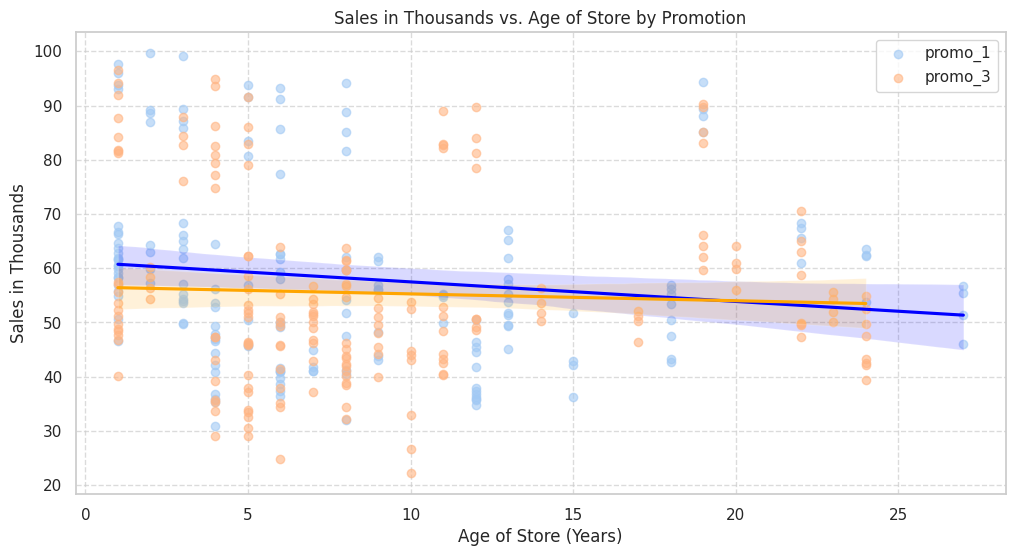


--- Correlation between Sales and AgeOfStore for Promotions 1 and 3 ---
`promo_1`: Pearson correlation between Sales and AgeOfStore = -0.145 (p-value: 0.058)
`promo_3`: Pearson correlation between Sales and AgeOfStore = -0.050 (p-value: 0.493)


In [18]:
# Filter for Promotion 1 and 3
df_promo1_3 = df[df['Promotion'].isin(["promo_1", "promo_3"])]
plt.figure(figsize=(12, 6))

# Scatter plot with regression line for `promo_1`
sns.regplot(x='AgeOfStore', y='SalesInThousands', data=df_promo1_3[df_promo1_3['Promotion'] =='promo_1'],
            scatter_kws={'alpha':0.6}, line_kws={'color':'blue'}, label='promo_1')

# Scatter plot with regression line for `promo_3`
sns.regplot(x='AgeOfStore', y='SalesInThousands', data=df_promo1_3[df_promo1_3['Promotion'] == 'promo_3'],
            scatter_kws={'alpha':0.6}, line_kws={'color':'orange'}, label='promo_3')

plt.title('Sales in Thousands vs. Age of Store by Promotion')
plt.xlabel('Age of Store (Years)')
plt.ylabel('Sales in Thousands')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


# --- Calculating Correlation Coefficients ---
print("\n--- Correlation between Sales and AgeOfStore for Promotions 1 and 3 ---")

# For `promo_1`
sales_promo1 = df_promo1_3[df_promo1_3['Promotion'] == "promo_1"]['SalesInThousands']
age_promo1 = df_promo1_3[df_promo1_3['Promotion'] == "promo_1"]["AgeOfStore"]
corr_promo1, p_corr_promo1 = pearsonr(sales_promo1, age_promo1)
print(f"`promo_1`: Pearson correlation between Sales and AgeOfStore = {corr_promo1:.3f} (p-value: {p_corr_promo1:.3f})")

# For `promo_3`
sales_promo3 = df_promo1_3[df_promo1_3['Promotion'] == "promo_3"]['SalesInThousands']
age_promo3 = df_promo1_3[df_promo1_3['Promotion'] == "promo_3"]['AgeOfStore']
corr_promo3, p_corr_promo3 = pearsonr(sales_promo3, age_promo3)
print(f"`promo_3`: Pearson correlation between Sales and AgeOfStore = {corr_promo3:.3f} (p-value: {p_corr_promo3:.3f})")

**Visual Observations from the Plot:**

* For `promo_1`, the blue regression line shows a very slight downward trend as `AgeOfStore` increases. This suggests a very weak tendency for sales to slightly decrease as stores get older under `promo_1`.

* For `promo_3`, the orange regression line also shows a very slight downward trend, but it appears even flatter than `promo_1`'s line.

Overall, visually, there doesn't appear to be a dramatic or strong linear relationship between `AgeOfStore` and `SalesInThousands` for either promotion, nor a significant difference in these trends between `promo_1` and `promo_3`.

**Correlation Coefficients and interpretation**

I also calculated the Pearson correlation coefficient between `SalesInThousands` and `AgeOfStore` for each promotion:

* `promo_1`: Pearson correlation = -0.145 (p-value: 0.058) which is a very weak negative correlation. The p-value of 0.058 is just above the conventional significance level of 0.05. This suggests that there's a barely non-significant tendency for sales to decrease as the store ages under `promo_1`.

* `promo_3`: Pearson correlation = -0.050 (p-value: 0.493) which is even weaker and also negative. The p-value of 0.493 is high, indicating no statistically significant linear relationship between sales and store age for `promo_3`.

**Is one promotion better for newer stores?**

Based on both the visual analysis of the scatter plot with regression lines and the calculated correlation coefficients:

* There's no strong evidence to suggest a significant linear correlation between store age and sales for either `promo_1` or `promo_3`.

* Neither promotion clearly shows a strong benefit for newer stores over older stores, or vice versa, in a linearly dependent way. The sales performance of both promotions seems relatively stable across different store ages.

* The very slight negative trend observed for `promo_1` is not statistically strong enough (p-value=0.058) to make a definitive claim that it performs worse in older stores or better in newer stores.

Therefore, we **do not find strong evidence to suggest that one promotion (1 or 3) is significantly "better for some stores" than the other**, purely based on the linear relationship between sales and age of store in this dataset. Their performance relative to store age appears quite similar and not strongly correlated.

#### Second we go with `MarketSize`

As market sise is categorical data and inheritly will have some differences between groups I will use swarm plot with box plot to visualize dependencies.

Promotion     promo_1    promo_3
MarketSize                      
Large       75.235893  77.203958
Medium      47.672604  45.468879
Small       60.162500  59.514167


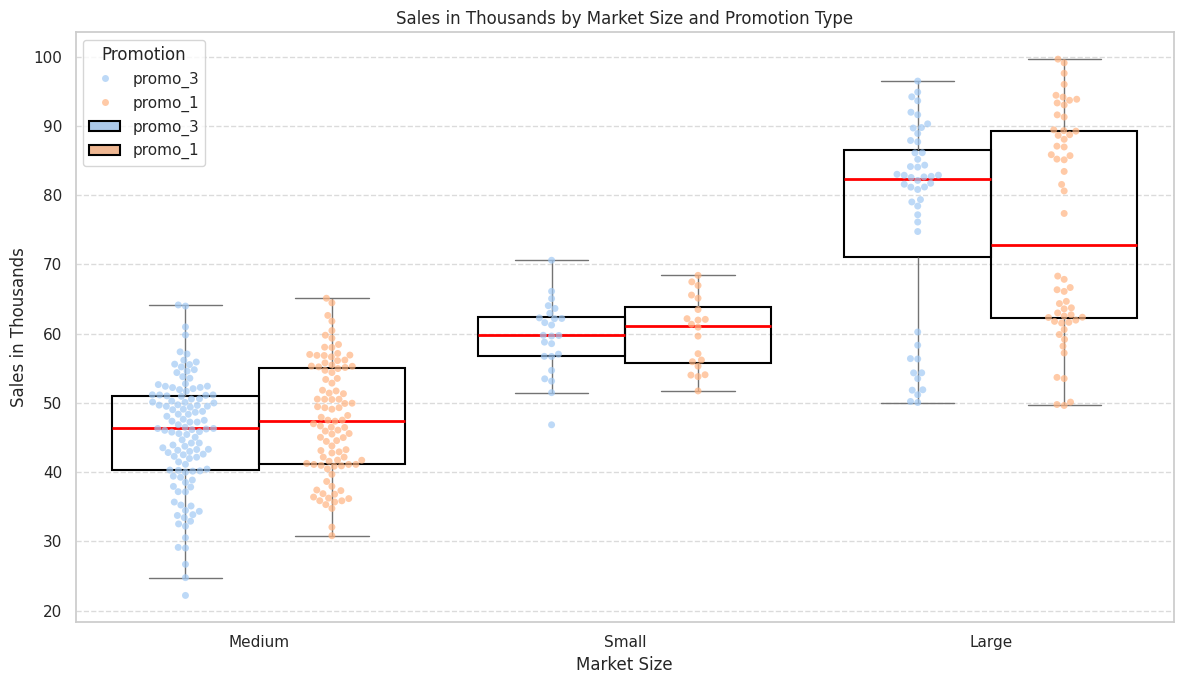

In [19]:
plt.figure(figsize=(12, 7))

# Create a swarmplot to show individual data points
sns.swarmplot(x='MarketSize', y='SalesInThousands', hue='Promotion',
              data=df_promo1_3, dodge=True, alpha=0.7)

# Overlay with a boxplot for clearer distribution and medians/quartiles
sns.boxplot(x='MarketSize', y='SalesInThousands', hue='Promotion',
            data=df_promo1_3, dodge=True,
            boxprops={'facecolor':'None', 'edgecolor':'black', 'linewidth':1.5},
            flierprops={'marker':'o', 'markerfacecolor':'none', 'markeredgecolor':'none'},
            medianprops={'color':'red', 'linewidth':2})


plt.title('Sales in Thousands by Market Size and Promotion Type')
plt.xlabel('Market Size')
plt.ylabel('Sales in Thousands')
plt.legend(title='Promotion')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

mean_sales_by_market_promo = df_promo1_3.groupby(['MarketSize', 'Promotion'])['SalesInThousands'].mean().unstack()
print(mean_sales_by_market_promo)

**Interpretation:**

* Large Markets: `promo_3` has a slightly higher mean sales (77.20K) than `promo_1` (75.24K), but this difference is small.

*  Medium Markets: `promo_1` has a slightly higher mean sales (47.67K) than `promo_3` (45.47K), again a small difference.

* Small Markets: `promo_1` has a slightly higher mean sales (60.16K) than `promo_3` (59.51K), also a small difference.


Based on both the visual analysis and the mean sales figures, there is no strong evidence to suggest that either `promo_1` or `promo_3` is significantly better for a particular market size than the other. While there are minor differences in means, the overlapping distributions and relatively small mean differences across market sizes suggest that their performance is quite comparable within each market size category. Both promotions tend to perform best in Large markets, followed by Small, and then Medium markets.

# 8. Conclusion

My analysis aimed to determine the effectiveness of different marketing promotions (`promo_1`, 2, and 3) on sales performance, also considering store characteristics like MarketSize and AgeOfStore.

**Overall Effect of Promotions:**

* The One-Way ANOVA test revealed a statistically significant difference in mean sales among the three promotion types (F-statistic: 21.953, p-value: 0.000). This indicates that the type of promotion **does have** a significant impact on sales.

**Specific Promotion Comparisons (Tukey's HSD with Confidence Intervals):**

* `promo_1` vs. `promo_2`: There is a statistically significant difference. `promo_1` led to significantly higher mean sales than `promo_2`. The 95% confidence interval for the mean difference (`promo_1` - `promo_2`) is [-14.7738, -6.7654], meaning `promo_1`'s sales are estimated to be between $6,765.40 and $14,773.80 higher per week than `promo_2`'s.

* `promo_1` vs. `promo_3`: There is no statistically significant difference in mean sales. The 95% confidence interval for the mean difference (`promo_1` - `promo_3`) is [-6.7388, 1.2697], indicating that zero difference is plausible between these two.

* `promo_2` vs. `promo_3`: There is a statistically significant difference. `promo_3` led to significantly higher mean sales than `promo_2`. The 95% confidence interval for the mean difference (`promo_2` - `promo_3`) is [4.1208, 11.9493], meaning `promo_3`'s sales are estimated to be between $4,120.80 and $11,949.30 higher per week than `promo_2`'s.

**Promotion Distribution & Performance by Market Size:**

* Performance: Visual and numerical analysis of mean sales across market sizes (Large, Medium, Small) for Promotions 1 and 3 revealed no strong evidence that either promotion is significantly better for a particular market size. Both promotions tend to yield the highest sales in Large markets, followed by Small markets, and then Medium markets. Their relative performance (Promo 1 vs. Promo 3) remains consistent across market sizes.

**Promotion Performance by Age of Store:**

* Correlation analysis (Pearson r) between SalesInThousands and AgeOfStore for both `promo_1` (r = -0.145, p-value: 0.058) and `promo_3` (r = -0.050, p-value: 0.493) showed very weak to no statistically significant linear correlation.

* This suggests that the age of a store does not have a strong linear relationship with sales performance under either `promo_1` or `promo_3`. I found no clear evidence that one promotion is significantly "better for any stores" than the other, as their sales impacts were relatively stable across different store ages.



**Recap:** While the normality assumption for ANOVA was violated, the large sample sizes for each promotion group (N > 170) provide robustness against this violation. Crucially, the assumption of homogeneity of variances was met (Levene's test p-value: 0.282).

Summary of Key Findings:

* `promo_2` is the least effective among the three promotions.

* `promo_1` and `promo_3` are equally effective in driving sales, and both are significantly better than `promo_2`.

* The effectiveness of `promo_1` and `promo_3` does not appear to be significantly influenced by the market size or the age of the store.

**Recommendations:**

Based on these comprehensive findings, here are the refined recommendations for marketing strategy:

* Discontinue or Heavily Re-evaluate `promo_2`: Given its consistent underperformance compared to the other two promotions across all analyses, `promo_2` should be discontinued or undergo a significant redesign and retesting.

* Prioritize `promo_1` or `promo_3` for Future Campaigns: Both `promo_1` and `promo_3` have demonstrated statistically similar and superior sales performance compared to `promo_2`. From a statistical perspective, either can be confidently rolled out for future campaigns.

* Consider Non-Sales Factors for Choosing Between `promo_1` and 3: Since both promotions are equally effective in terms of sales:

    * Cost-effectiveness: Choose the promotion that has a lower cost of implementation per unit of sales generated.

    * Ease of Implementation: Select the promotion that is logistically simpler or less resource-intensive to deploy across your stores.

    * Strategic Alignment: Consider which promotion better aligns with long-term brand goals, customer acquisition strategies, or operational capabilities.

    * Customer Lifetime Value (CLTV): If data on repeat purchases or customer segments were available, further analysis could determine if one promotion attracts higher-value customers.

**No Specific Targeting by Market Size or Age of Store is Necessary: My analysis found no statistically significant interaction or specific benefit of `promo_1` or 3 for particular market sizes or store ages. Therefore, these promotions can likely be applied broadly without needing to tailor them to specific market size categories or the age of the store.**
